<a href="https://colab.research.google.com/github/ContiPaolo/EKF-SINDy/blob/main/notebooks/SelkovModel_OnlineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
###########################  INSTALL EKF-SINDY (Colab only)  ###########################
# Colab: run this cell first. After installing, the runtime restarts automatically (to load the
# pinned numpy/scipy versions); then run the whole notebook, this cell will be skipped.
# Locally: run `uv sync --all-extras` in the repository and select the `.venv` kernel.
import sys

if "google.colab" in sys.modules:
    try:
        import ekfsindy  # noqa: F401
    except ImportError:
        %pip install "ekfsindy[notebooks] @ git+https://github.com/ContiPaolo/EKF-SINDy"
        import os

        os.kill(os.getpid(), 9)

In [2]:
%matplotlib inline

import warnings

warnings.filterwarnings("ignore", message="pkg_resources is deprecated")  # raised by pysindy 1.7.5

###########################                LIBRARIES                ###########################
import matplotlib.pyplot as plt
import numpy as np
import pysindy as ps
from scipy.integrate import odeint

from ekfsindy import AugmentedEKF, SparseModel, SymbolicLibrary, observation, systems
from ekfsindy.data import add_noise_with_snr
from ekfsindy.plotting import plot_estimates, plot_phase_space

seed = 1

# Selkov Model

The Selkov model equations are:

\begin{aligned}
\quad u_1' &= \rho - \sigma_1 u_1 - b_{122,1} u_1  u_2^2, \\
\quad u_2' &= \sigma_2  u_1 -k_{2}  u_2 + b_{122,2}  u_1  u_2^2.
\end{aligned}


The equilibrium point is:

$(x_0, y_0) = \left(\frac{\rho}{\sigma + \rho^2}, \rho\right)$

### Hopf Bifurcations and Stability Regions

By varying $\rho$, two Hopf bifurcations occur, defining three regions of stability:

- $\rho < 0.41$: Stable fixed point.
- $0.41 < \rho < 0.8$: Stable limit cycle.
- $\rho > 0.8$: Stable fixed point.

The bifurcation values of $\rho$ are:
- $\rho_1 = 0.41$
- $\rho_2 = 0.8$

In [3]:
# Parameters of the Selkov model for the offline training (ODE in `ekfsindy.systems.selkov`)
system = {
    "rho": 0.92,
    "sigma1": 0.10,
    "sigma2": 0.10,
    "k2": 1.0,
    "b122_1": 1.0,
    "b122_2": 1.0,
    "t0": 0.00,
    "T_train": 100.0,
    "dt": 0.10,
}

In [4]:
######################       GENERATE TRAINING DATA       ######################
t_train = np.arange(system["t0"], system["T_train"], system["dt"])

# Random initial conditions
np.random.seed(seed=seed)
u1_0 = np.random.normal(0.2, 2, 20)
u2_0 = np.random.normal(0.2, 2, 20)

n_train = 16
X_train = [odeint(systems.selkov, [u1_0[i], u2_0[i]], t_train, args=(system,)) for i in range(n_train)]

######################      OFFLINE SINDy       ######################
sindy = ps.SINDy(feature_names=["u1", "u2"],
                 feature_library=ps.PolynomialLibrary(degree=3),
                 optimizer=ps.STLSQ(threshold=5e-2))
sindy.fit(X_train, t=system["dt"], multiple_trajectories=True)
sindy.print()

(u1)' = 0.923 1 + -0.094 u1 + -0.076 u1 u2 + -0.929 u1 u2^2
(u2)' = 0.108 u1 + -0.934 u2 + 0.918 u1 u2^2


In [5]:
# Online phase: rho is swept from rho_start to rho_end over [T1, T1 + T_sweep].
# The online assimilation runs up to T = 300, much longer than the training time T_train = 100.
system.update({
    "rho_start": 0.92,
    "rho_end": 0.70,
    "T1": 50.0,
    "T_sweep": 50.0,
    "T": 300.0,
})

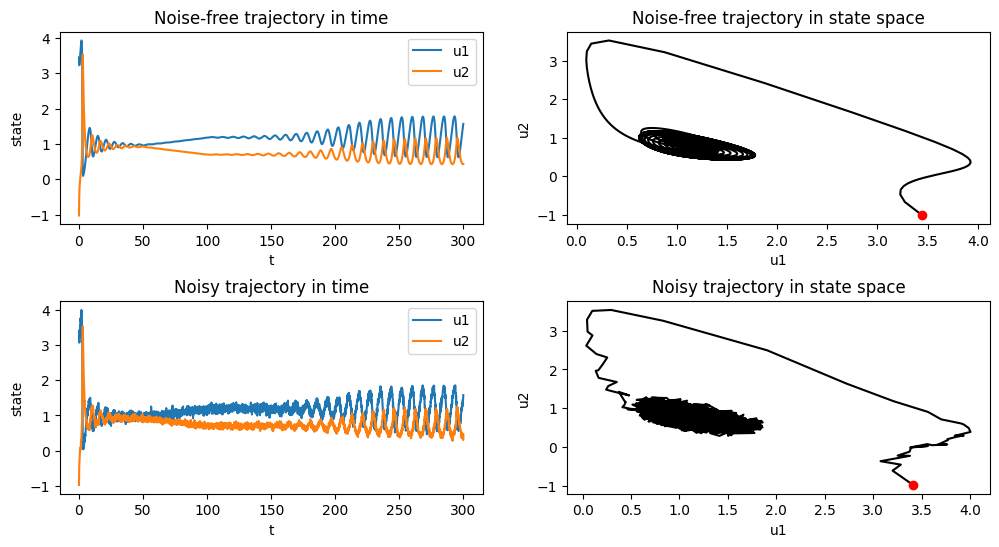

In [6]:
######################       GENERATE DATA for EKF       ######################
t = np.arange(system["t0"], system["T"], system["dt"])

np.random.seed(seed=seed)
y0 = [np.random.normal(0.2, 2, 1)[0], np.random.normal(0.2, 2, 1)[0]]
X = odeint(systems.selkov, y0, t, args=(system, True))  # noise-free reference

# Noisy measurements of both states (SNR = 25 dB)
Y = np.column_stack([add_noise_with_snr(X[:, 0], 25), add_noise_with_snr(X[:, 1], 25)])

fig, axes = plt.subplots(2, 2, figsize=[12, 6])
for row, (data, kind) in enumerate([(X, "Noise-free"), (Y, "Noisy")]):
    axes[row, 0].plot(t, data[:, 0], label="u1")
    axes[row, 0].plot(t, data[:, 1], label="u2")
    axes[row, 0].set(xlabel="t", ylabel="state", title=f"{kind} trajectory in time")
    axes[row, 0].legend()
    axes[row, 1].plot(data[:, 0], data[:, 1], "black")
    axes[row, 1].plot(data[0, 0], data[0, 1], "ro")
    axes[row, 1].set(xlabel="u1", ylabel="u2", title=f"{kind} trajectory in state space")
plt.subplots_adjust(hspace=0.4)
plt.show()

In [7]:
######################      SYMBOLIC SINDy LIBRARY       ######################
# The pysindy feature names are parsed into SymPy expressions; the library is compiled to JAX,
# so its Jacobian (and the EKF Jacobians) come from automatic differentiation.
library = SymbolicLibrary.from_feature_names(sindy.get_feature_names(), ["u1", "u2"])
print("SINDy library terms:", list(library.expressions))
print("\nSymbolic Jacobian d(theta)/d(u1, u2):")
library.symbolic_jacobian()

SINDy library terms: [1, u1, u2, u1**2, u1*u2, u2**2, u1**3, u1**2*u2, u1*u2**2, u2**3]

Symbolic Jacobian d(theta)/d(u1, u2):


Matrix([
[      0,       0],
[      1,       0],
[      0,       1],
[   2*u1,       0],
[     u2,      u1],
[      0,    2*u2],
[3*u1**2,       0],
[2*u1*u2,   u1**2],
[  u2**2, 2*u1*u2],
[      0, 3*u2**2]])

The model identified by SINDy offline has the form

\begin{aligned}
\quad u_1' &= \tilde{\rho} - \tilde{\sigma}_1 u_1 + {{\color{red}{\tilde{a}_{12,1} u_1u_2}}}- \tilde{b}_{122,1} u_1 u_2^2, \\
\quad u_2' &= \tilde{\sigma}_2 u_1  -\tilde{k}_{2,2} u_2 + \tilde{b}_{122,2} u_1  u_2^2,
\end{aligned}

where the term ${\tilde{a}_{12,1} u_1u_2}$ is (erroneously) indicated as relevant (non zero), while it is absent in the original model, i.e. $a_{12,1}=0$.

All the coefficients are stored in the matrix $\Xi$ which is given by `coeffs`.
A `SparseModel` wraps $\Xi$ together with the symbolic library and the list of entries $\tilde{\Xi}$ to monitor; all other entries $\Xi_0$ are kept frozen. The EKF tracks the augmented state $[u_1, u_2, \tilde{\Xi}]$ and obtains all Jacobians by automatic differentiation through the library.

In [8]:
#%% Monitor all the nonzero coefficients identified offline
model = SparseModel.from_pysindy(sindy, library, estimated="nonzero")
model.print()
print("\nMonitored coefficients:", model.estimated_names)

(u1)' = -0.929*u1*u2**2 - 0.076*u1*u2 - 0.094*u1 + 0.923
(u2)' = 0.918*u1*u2**2 + 0.108*u1 - 0.934*u2

Monitored coefficients: ['u1: 1', 'u1: u1', 'u1: u1 u2', 'u1: u1 u2^2', 'u2: u1', 'u2: u2', 'u2: u1 u2^2']



In this case we monitor all the nonzero coefficients identified by SINDy, namely
$$[\tilde{\rho}, \tilde{\sigma_1}, \tilde{a}_{12,1}, \tilde{b}_{122,1}, \tilde{\sigma_2}, \tilde{k}_{2,2}, \tilde{b}_{122,2}],$$
and collect them in $\tilde{\Xi}$.

All the other coefficients (the ones set to zero by the offline SINDy) are kept frozen to zero, not monitored and collected in $\Xi_0$.

In [9]:
# Coefficient names and ground-truth values (rho varies in time, see `systems.rho_schedule`)
coeff_names = ["rho", "sigma_1", "a12_1", "b122_1", "sigma_2", "k2_2", "b122_2"]
true_coeff = [systems.rho_schedule(t, system), -system["sigma1"], 0.0, -system["b122_1"],
              system["sigma2"], -system["k2"], system["b122_2"]]

In [10]:
# %% Filter tuning
# Initial uncertainty
p0_u = 1e-8
p0_xi = [5e-4, 1e-3, 5e-4, 1e-3, 1e-4, 5e-4, 1e-3]  # rho, sigma_1, a12_1, b122_1, sigma_2, k2_2, b122_2
# Process noise
q_u = [8e-7, 8e-7]
q_xi = [5e-6, 1e-9, 1e-10, 1e-10, 1e-11, 1e-9, 1e-12]
# Measurement noise
r_u = [5e-4, 5e-4]

ekf = AugmentedEKF(model, observation.select_states([0, 1]),  # both states are measured
                   Q=np.diag(q_u + q_xi), R=np.diag(r_u), dt=system["dt"], integrator="rk4")
z0 = model.augmented_state(Y[0])  # [u1, u2, monitored coefficients]
P0 = np.diag([p0_u] * 2 + p0_xi)

In [11]:
result = ekf.run(z0, P0, Y)

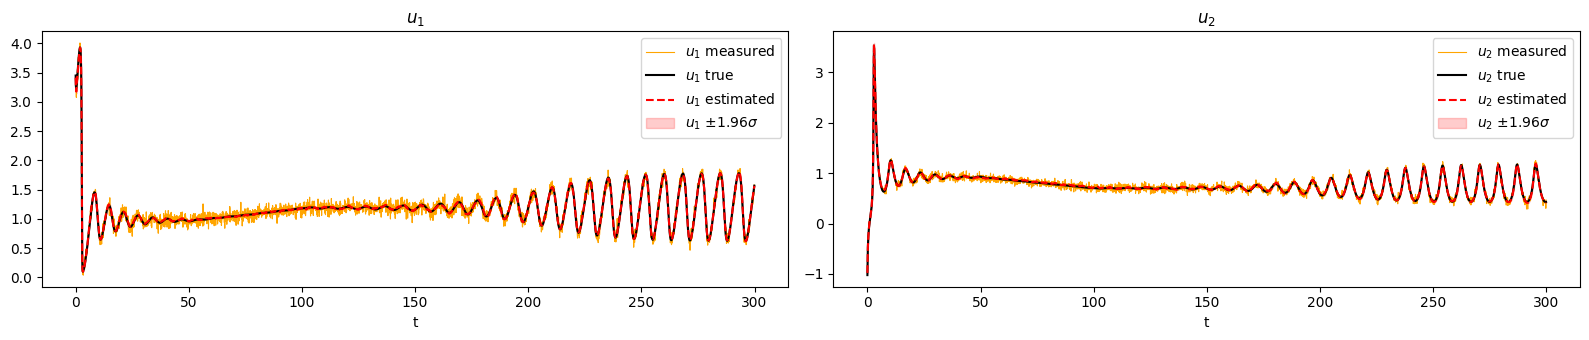

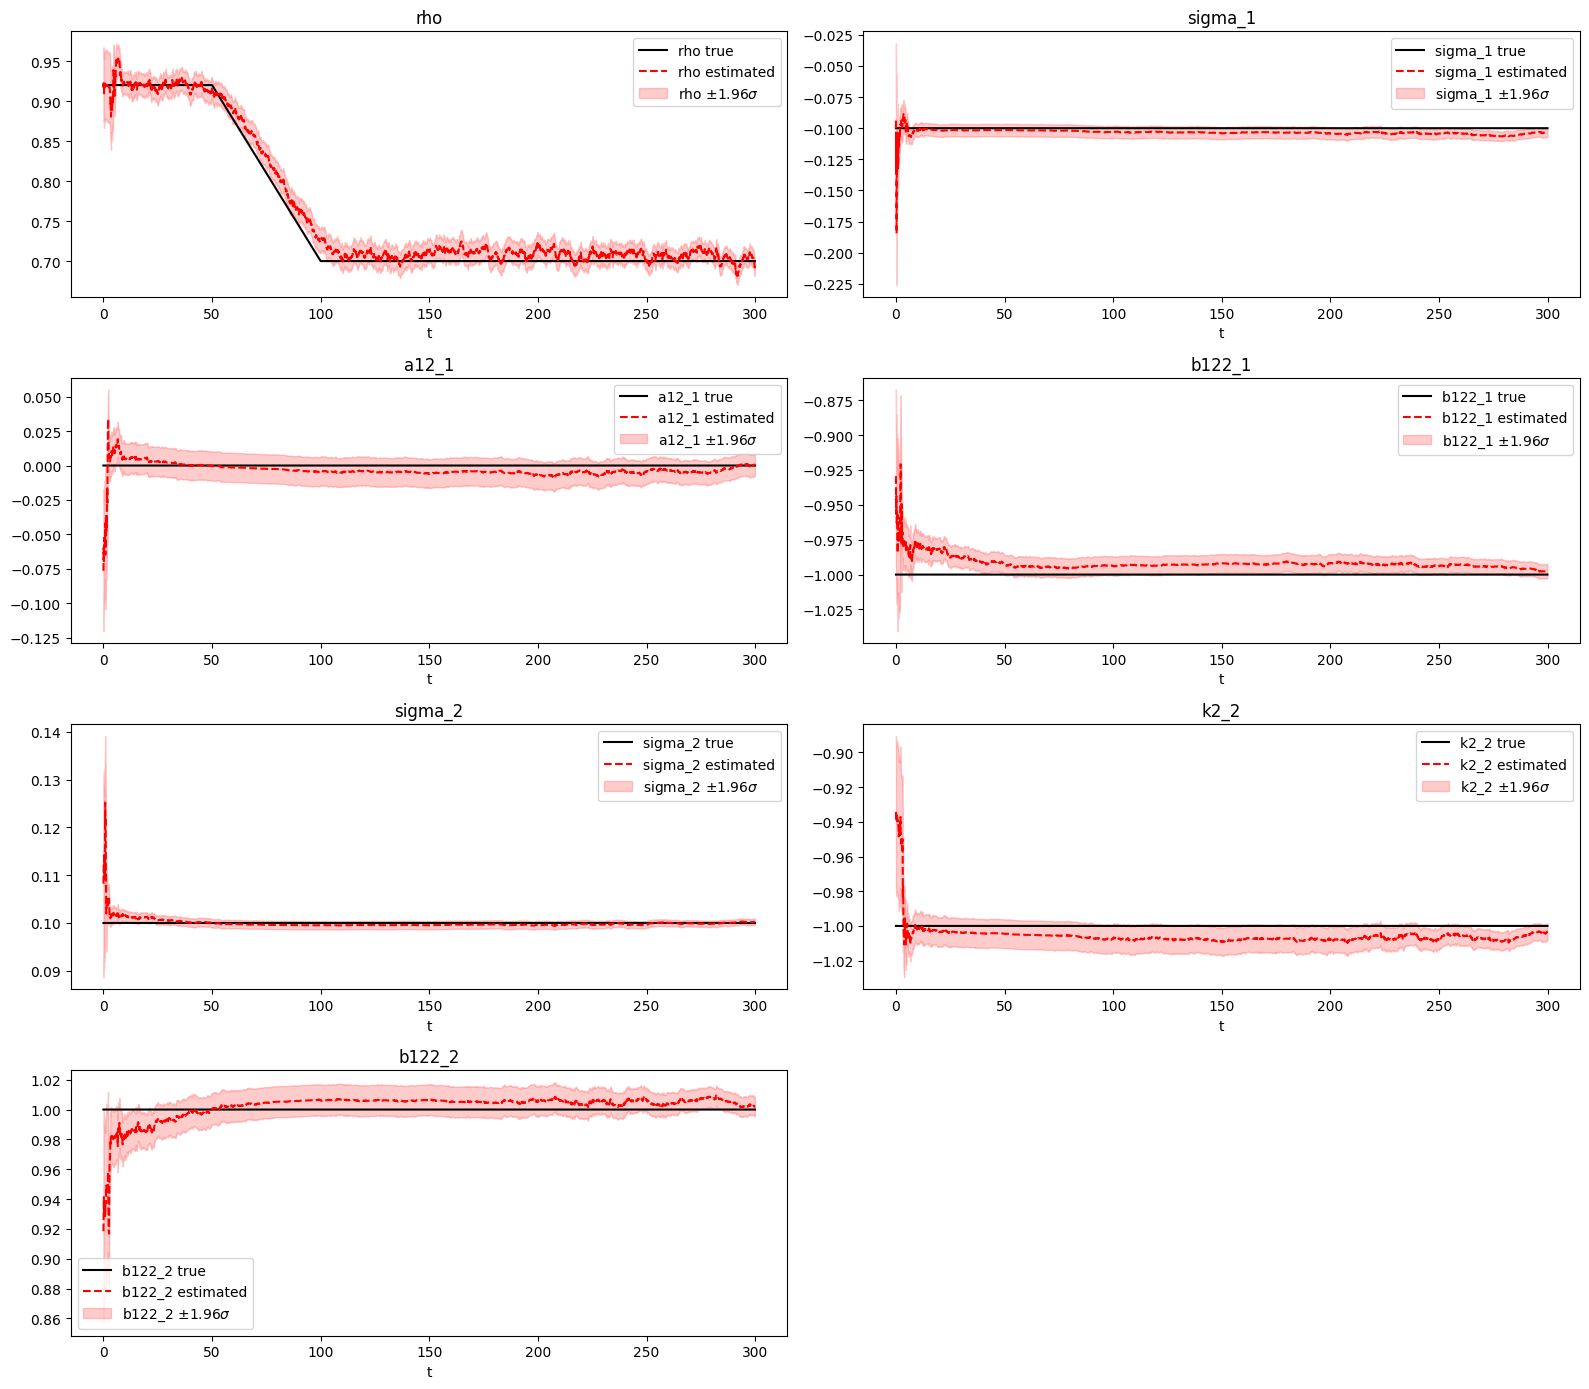

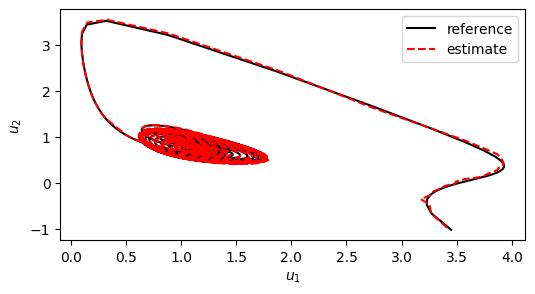

In [12]:
def plot_selkov(result, coeff_names, true_coeff):
    plot_estimates(t, result, [0, 1], ["$u_1$", "$u_2$"], truths=[X[:, 0], X[:, 1]],
                   measured=[Y[:, 0], Y[:, 1]])
    plot_estimates(t, result, range(2, 2 + len(coeff_names)), coeff_names, truths=true_coeff)
    plt.show()
    plt.figure(figsize=[6, 3])
    plot_phase_space(X, result)
    plt.show()


plot_selkov(result, coeff_names, true_coeff)

### **References**

[1] Rosafalco, Conti, Manzoni, Mariani, Frangi. [Online learning in bifurcating dynamic systems via SINDy and Kalman filtering](https://link.springer.com/article/10.1007/s11071-025-11029-y), Nonlinear Dynamics (2025).

[2] Rosafalco, Conti, Manzoni, Mariani, Frangi. [EKF-SINDy: Empowering the extended Kalman filter with sparse identification of nonlinear dynamics](https://www.sciencedirect.com/science/article/abs/pii/S0045782522007678?via%3Dihub), Computer methods in applied mechanics and engineering (2024).

⭐ Leave a star to the github repos if you enjoyed :)

### **Extra**
To evaluate the robustness of the online procedure, we have adopted a *poor* SINDy model for the Selkov dynamics by setting the threshold parameter $L=0.2$ instead of $L=0.05$.

The model obtained with $L=0.2$ deviates significantly more from the reference compared to the one determined with $L=0.05$. Notably, this model entirely omits the $x_1$ term, which is weighted by the coefficients $\sigma_1$ and $\sigma_2$ in $f_1$ and $f_2$, respectively.

As it is shown in the following, the procedure demonstrates remarkable robustness, as the identification outcomes are once again satisfactory, successfully recovering the correct values of the missing terms $\sigma_1$ and $\sigma_2$. As unique warning, we observe that it has been necessary to initially set the values of $\sigma_1$ and $\sigma_2$ to $10^{-9}$, a small value but different from $0$, to ensure sensitivity to these parameters in the Jacobian matrix.

(u1)' = 0.787 1 + -0.959 u1 u2^2
(u2)' = -0.865 u2 + 0.960 u1 u2^2

Monitored coefficients: ['u1: 1', 'u1: u1', 'u1: u1 u2^2', 'u2: u1', 'u2: u2', 'u2: u1 u2^2']


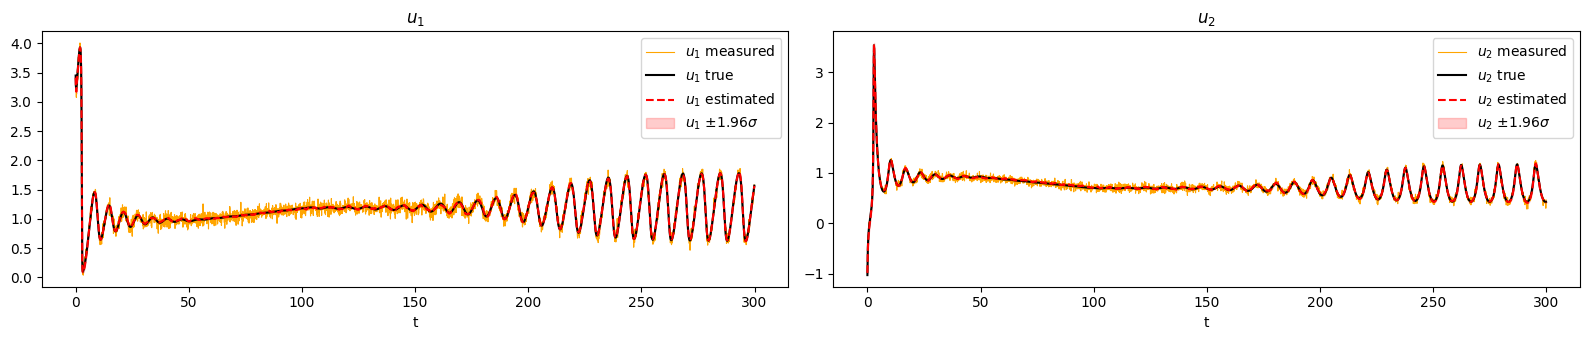

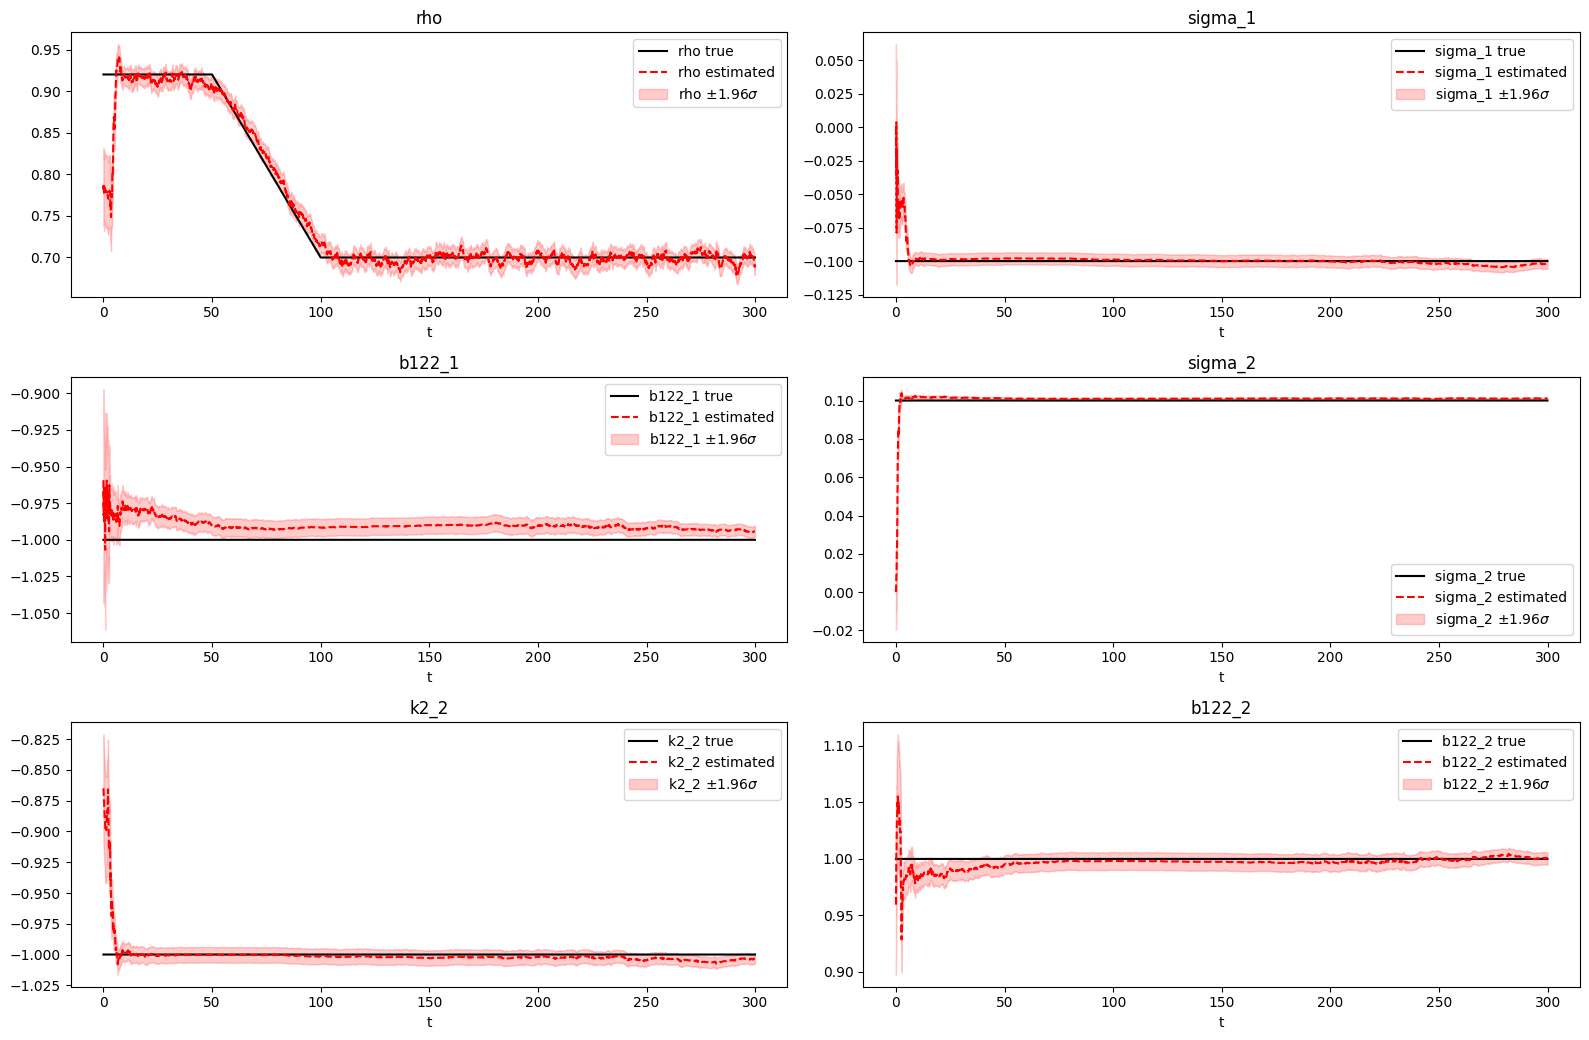

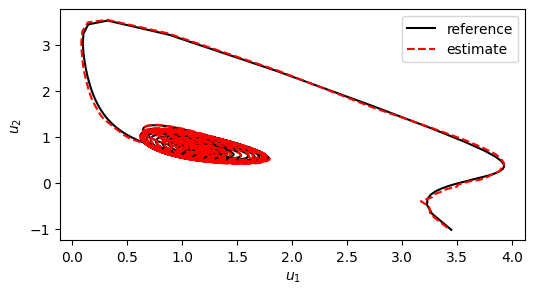

In [13]:
# ######################      Offline SINDy (poor model)     ######################
sindy_poor = ps.SINDy(feature_names=["u1", "u2"],
                      feature_library=ps.PolynomialLibrary(degree=3),
                      optimizer=ps.STLSQ(threshold=0.2))
sindy_poor.fit(X_train, t=system["dt"], multiple_trajectories=True)
sindy_poor.print()

# Give the missing linear terms 'u1' a tiny nonzero value so that they are monitored
coeffs_poor = sindy_poor.coefficients().copy()
coeffs_poor[0, 1] = coeffs_poor[1, 1] = 1e-9
model_poor = SparseModel.from_pysindy(sindy_poor, library, estimated="nonzero",
                                      coefficients=coeffs_poor)
print("\nMonitored coefficients:", model_poor.estimated_names)

coeff_names_poor = ["rho", "sigma_1", "b122_1", "sigma_2", "k2_2", "b122_2"]
true_coeff_poor = [systems.rho_schedule(t, system), -system["sigma1"], -system["b122_1"],
                   system["sigma2"], -system["k2"], system["b122_2"]]

# %% Filter tuning
p0_xi = [5e-4, 1e-3, 1e-3, 1e-4, 5e-4, 1e-3]  # rho, sigma_1, b122_1, sigma_2, k2_2, b122_2
q_xi = [5e-6, 1e-9, 1e-10, 1e-11, 1e-9, 1e-12]

ekf_poor = AugmentedEKF(model_poor, observation.select_states([0, 1]),
                        Q=np.diag(q_u + q_xi), R=np.diag(r_u), dt=system["dt"], integrator="rk4")
result_poor = ekf_poor.run(model_poor.augmented_state(Y[0]), np.diag([p0_u] * 2 + p0_xi), Y)

plot_selkov(result_poor, coeff_names_poor, true_coeff_poor)